In [1]:
pip install mlflow xgboost scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import mlflow
import mlflow.sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

print("All imports successful")

All imports successful


In [ ]:
base = r"C:\Users\asifs\Desktop\Project MLops alpha\E-Commerce-Shipping-Prediction\processed"

X_train = pd.read_csv(f"{base}\\X_train.csv")
X_test  = pd.read_csv(f"{base}\\X_test.csv")
y_train = pd.read_csv(f"{base}\\y_train.csv").squeeze()
y_test  = pd.read_csv(f"{base}\\y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train classes:", y_train.value_counts().to_dict())
print("y_test  classes:", y_test.value_counts().to_dict())

X_train: (40000, 8)
X_test:  (10000, 8)
y_train classes: {1: 32050, 0: 6004, 2: 1946}
y_test  classes: {1: 8012, 0: 1501, 2: 487}


In [18]:
import os
os.environ.pop("MLFLOW_TRACKING_URI", None)

import importlib
import mlflow
importlib.reload(mlflow)

mlflow.set_tracking_uri("file:///C:/Users/Vivek Kumar Singh/mlruns")
mlflow.set_experiment("shipping-prediction")
print("MLflow ready")

2026/04/27 12:38:52 INFO mlflow.tracking.fluent: Experiment with name 'shipping-prediction' does not exist. Creating a new experiment.


MLflow ready


In [19]:
with mlflow.start_run(run_name="LogisticRegression_baseline"):
    model_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model_lr.fit(X_train, y_train)
    y_pred_lr = model_lr.predict(X_test)
    f1_lr = f1_score(y_test, y_pred_lr, average='weighted')

    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_metric("f1_weighted", f1_lr)
    mlflow.sklearn.log_model(model_lr, "model")

    print("=== Logistic Regression ===")
    print(f"F1 Weighted: {f1_lr:.4f}")
    print()
    print(classification_report(y_test, y_pred_lr,
          target_names=['Delayed','Delivered','Returned']))

2026/04/27 12:39:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/27 12:39:54 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== Logistic Regression ===
F1 Weighted: 0.2174

              precision    recall  f1-score   support

     Delayed       0.16      0.44      0.23      1501
   Delivered       0.81      0.13      0.22      8012
    Returned       0.05      0.46      0.09       487

    accuracy                           0.19     10000
   macro avg       0.34      0.34      0.18     10000
weighted avg       0.68      0.19      0.22     10000



In [20]:
with mlflow.start_run(run_name="RandomForest_v1"):
    model_rf = RandomForestClassifier(n_estimators=100, max_depth=10,
                                      class_weight='balanced',
                                      random_state=42, n_jobs=-1)
    model_rf.fit(X_train, y_train)
    y_pred_rf = model_rf.predict(X_test)
    f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

    mlflow.log_param("model_type", "RandomForest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("max_depth", 10)
    mlflow.log_metric("f1_weighted", f1_rf)
    mlflow.sklearn.log_model(model_rf, "model")

    print("=== Random Forest ===")
    print(f"F1 Weighted: {f1_rf:.4f}")
    print()
    print(classification_report(y_test, y_pred_rf,
          target_names=['Delayed','Delivered','Returned']))

2026/04/27 12:40:18 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/27 12:40:22 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== Random Forest ===
F1 Weighted: 0.6304

              precision    recall  f1-score   support

     Delayed       0.15      0.18      0.16      1501
   Delivered       0.80      0.71      0.75      8012
    Returned       0.05      0.11      0.07       487

    accuracy                           0.60     10000
   macro avg       0.33      0.33      0.33     10000
weighted avg       0.67      0.60      0.63     10000



In [21]:
with mlflow.start_run(run_name="XGBoost_v1"):
    model_xgb = XGBClassifier(n_estimators=200, max_depth=6,
                               learning_rate=0.1, eval_metric='mlogloss',
                               random_state=42, n_jobs=-1)
    model_xgb.fit(X_train, y_train)
    y_pred_xgb = model_xgb.predict(X_test)
    f1_xgb = f1_score(y_test, y_pred_xgb, average='weighted')

    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("learning_rate", 0.1)
    mlflow.log_metric("f1_weighted", f1_xgb)
    mlflow.sklearn.log_model(model_xgb, "model")

    print("=== XGBoost ===")
    print(f"F1 Weighted: {f1_xgb:.4f}")
    print()
    print(classification_report(y_test, y_pred_xgb,
          target_names=['Delayed','Delivered','Returned']))

2026/04/27 12:40:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/27 12:40:49 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== XGBoost ===
F1 Weighted: 0.7127

              precision    recall  f1-score   support

     Delayed       0.10      0.00      0.00      1501
   Delivered       0.80      1.00      0.89      8012
    Returned       0.00      0.00      0.00       487

    accuracy                           0.80     10000
   macro avg       0.30      0.33      0.30     10000
weighted avg       0.66      0.80      0.71     10000



In [22]:
from sklearn.utils import resample


df_train = X_train.copy()
df_train['target'] = y_train.values

class_0 = df_train[df_train['target'] == 0] 
class_1 = df_train[df_train['target'] == 1]  
class_2 = df_train[df_train['target'] == 2]  


class_0_up = resample(class_0, replace=True, n_samples=32050, random_state=42)
class_2_up = resample(class_2, replace=True, n_samples=32050, random_state=42)

df_balanced = pd.concat([class_0_up, class_1, class_2_up])
df_balanced = df_balanced.sample(frac=1, random_state=42)  

X_train_bal = df_balanced.drop('target', axis=1)
y_train_bal = df_balanced['target']

print("Balanced class distribution:")
print(y_train_bal.value_counts())

Balanced class distribution:
target
0    32050
1    32050
2    32050
Name: count, dtype: int64


In [23]:
with mlflow.start_run(run_name="XGBoost_balanced"):
    model_xgb2 = XGBClassifier(n_estimators=200, max_depth=6,
                                learning_rate=0.1, eval_metric='mlogloss',
                                random_state=42, n_jobs=-1)
    model_xgb2.fit(X_train_bal, y_train_bal)
    y_pred_xgb2 = model_xgb2.predict(X_test)
    f1_xgb2 = f1_score(y_test, y_pred_xgb2, average='weighted')

    mlflow.log_param("model_type", "XGBoost_balanced")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("balancing", "oversample")
    mlflow.log_metric("f1_weighted", f1_xgb2)
    mlflow.sklearn.log_model(model_xgb2, name="model")

    print("=== XGBoost Balanced ===")
    print(f"F1 Weighted: {f1_xgb2:.4f}")
    print()
    print(classification_report(y_test, y_pred_xgb2,
          target_names=['Delayed','Delivered','Returned']))

2026/04/27 12:43:03 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== XGBoost Balanced ===
F1 Weighted: 0.5371

              precision    recall  f1-score   support

     Delayed       0.15      0.28      0.20      1501
   Delivered       0.80      0.52      0.63      8012
    Returned       0.05      0.21      0.08       487

    accuracy                           0.47     10000
   macro avg       0.34      0.34      0.30     10000
weighted avg       0.67      0.47      0.54     10000



In [24]:
with mlflow.start_run(run_name="RandomForest_balanced"):
    model_rf2 = RandomForestClassifier(n_estimators=100, max_depth=10,
                                       random_state=42, n_jobs=-1)
    model_rf2.fit(X_train_bal, y_train_bal)
    y_pred_rf2 = model_rf2.predict(X_test)
    f1_rf2 = f1_score(y_test, y_pred_rf2, average='weighted')

    mlflow.log_param("model_type", "RandomForest_balanced")
    mlflow.log_param("balancing", "oversample")
    mlflow.log_metric("f1_weighted", f1_rf2)
    mlflow.sklearn.log_model(model_rf2, name="model")

    print("=== Random Forest Balanced ===")
    print(f"F1 Weighted: {f1_rf2:.4f}")
    print()
    print(classification_report(y_test, y_pred_rf2,
          target_names=['Delayed','Delivered','Returned']))

2026/04/27 12:43:23 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== Random Forest Balanced ===
F1 Weighted: 0.5390

              precision    recall  f1-score   support

     Delayed       0.16      0.26      0.20      1501
   Delivered       0.81      0.52      0.63      8012
    Returned       0.05      0.24      0.08       487

    accuracy                           0.47     10000
   macro avg       0.34      0.34      0.30     10000
weighted avg       0.67      0.47      0.54     10000



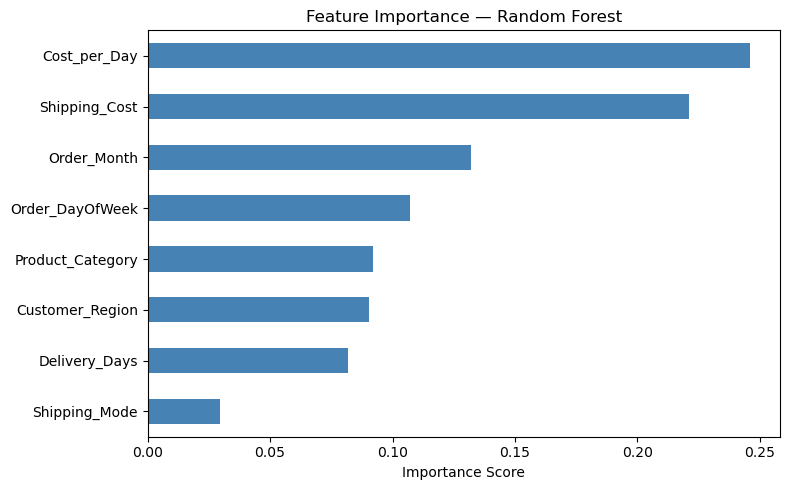

Cost_per_Day        0.246001
Shipping_Cost       0.221306
Order_Month         0.132025
Order_DayOfWeek     0.107074
Product_Category    0.091872
Customer_Region     0.090348
Delivery_Days       0.081954
Shipping_Mode       0.029419
dtype: float64


In [25]:
import matplotlib.pyplot as plt
import pandas as pd

feat_imp = pd.Series(model_rf2.feature_importances_,
                     index=X_train_bal.columns).sort_values(ascending=True)

feat_imp.plot(kind='barh', figsize=(8,5), color='steelblue')
plt.title("Feature Importance — Random Forest")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

print(feat_imp.sort_values(ascending=False))

In [26]:
# Create binary target — 1=On Time, 0=Not On Time
y_train_bin = (y_train == 1).astype(int)
y_test_bin  = (y_test  == 1).astype(int)

print("Binary train balance:")
print(y_train_bin.value_counts())
print()
print("Binary test balance:")
print(y_test_bin.value_counts())

Binary train balance:
0
1    32050
0     7950
Name: count, dtype: int64

Binary test balance:
0
1    8012
0    1988
Name: count, dtype: int64


In [27]:
# Balance binary dataset
df_train_bin = X_train.copy()
df_train_bin['target'] = y_train_bin.values

class_on  = df_train_bin[df_train_bin['target'] == 1]   # On time  32050
class_off = df_train_bin[df_train_bin['target'] == 0]   # Not on time 7950

class_off_up = resample(class_off, replace=True, 
                        n_samples=len(class_on), random_state=42)

df_bin_bal = pd.concat([class_on, class_off_up]).sample(frac=1, random_state=42)
X_train_bin = df_bin_bal.drop('target', axis=1)
y_train_bin_bal = df_bin_bal['target']

print("Balanced binary distribution:")
print(y_train_bin_bal.value_counts())

Balanced binary distribution:
target
0    32050
1    32050
Name: count, dtype: int64


In [28]:
with mlflow.start_run(run_name="XGBoost_binary"):
    model_bin = XGBClassifier(n_estimators=200, max_depth=6,
                              learning_rate=0.1, eval_metric='logloss',
                              random_state=42, n_jobs=-1)
    model_bin.fit(X_train_bin, y_train_bin_bal)
    y_pred_bin = model_bin.predict(X_test)
    f1_bin = f1_score(y_test_bin, y_pred_bin, average='weighted')

    mlflow.log_param("model_type", "XGBoost_binary")
    mlflow.log_param("target", "binary_ontime")
    mlflow.log_metric("f1_weighted", f1_bin)
    mlflow.sklearn.log_model(model_bin, name="model")

    print("=== XGBoost Binary (On Time vs Not) ===")
    print(f"F1 Weighted: {f1_bin:.4f}")
    print()
    print(classification_report(y_test_bin, y_pred_bin,
          target_names=['Not On Time', 'On Time']))

2026/04/27 12:44:54 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== XGBoost Binary (On Time vs Not) ===
F1 Weighted: 0.6158

              precision    recall  f1-score   support

 Not On Time       0.19      0.36      0.25      1988
     On Time       0.80      0.63      0.71      8012

    accuracy                           0.58     10000
   macro avg       0.50      0.50      0.48     10000
weighted avg       0.68      0.58      0.62     10000



In [29]:
# Reload original files and rebuild with better features
base = r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data\processed"
X_tr = pd.read_csv(f"{base}\\X_train.csv")
X_te = pd.read_csv(f"{base}\\X_test.csv")
y_tr = pd.read_csv(f"{base}\\y_train.csv").squeeze()
y_te = pd.read_csv(f"{base}\\y_test.csv").squeeze()

# Binary target
y_tr_bin = (y_tr == 1).astype(int)
y_te_bin = (y_te == 1).astype(int)

# Add interaction features
X_tr['Cost_x_Days']    = X_tr['Shipping_Cost'] * X_tr['Delivery_Days']
X_tr['Cost_x_Mode']    = X_tr['Shipping_Cost'] * X_tr['Shipping_Mode']
X_tr['Days_x_Mode']    = X_tr['Delivery_Days'] * X_tr['Shipping_Mode']

X_te['Cost_x_Days']    = X_te['Shipping_Cost'] * X_te['Delivery_Days']
X_te['Cost_x_Mode']    = X_te['Shipping_Cost'] * X_te['Shipping_Mode']
X_te['Days_x_Mode']    = X_te['Delivery_Days'] * X_te['Shipping_Mode']

print("New features added. Shape:", X_tr.shape)
print(X_tr.columns.tolist())

New features added. Shape: (40000, 11)
['Customer_Region', 'Product_Category', 'Shipping_Mode', 'Shipping_Cost', 'Delivery_Days', 'Order_Month', 'Order_DayOfWeek', 'Cost_per_Day', 'Cost_x_Days', 'Cost_x_Mode', 'Days_x_Mode']


In [30]:
from sklearn.utils import resample

df_tr = X_tr.copy()
df_tr['target'] = y_tr_bin.values

c1 = df_tr[df_tr['target']==1]
c0 = df_tr[df_tr['target']==0]
c0_up = resample(c0, replace=True, n_samples=len(c1), random_state=42)
df_bal = pd.concat([c1, c0_up]).sample(frac=1, random_state=42)

X_tr_bal = df_bal.drop('target', axis=1)
y_tr_bal  = df_bal['target']

with mlflow.start_run(run_name="XGBoost_tuned_binary"):
    model_tuned = XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
    model_tuned.fit(X_tr_bal, y_tr_bal)
    y_pred_tuned = model_tuned.predict(X_te)
    f1_tuned = f1_score(y_te_bin, y_pred_tuned, average='weighted')

    mlflow.log_param("model_type", "XGBoost_tuned")
    mlflow.log_param("n_estimators", 500)
    mlflow.log_param("max_depth", 4)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("new_features", "Cost_x_Days, Cost_x_Mode, Days_x_Mode")
    mlflow.log_metric("f1_weighted", f1_tuned)
    mlflow.sklearn.log_model(model_tuned, name="model")

    print("=== XGBoost Tuned + New Features ===")
    print(f"F1 Weighted: {f1_tuned:.4f}")
    print()
    print(classification_report(y_te_bin, y_pred_tuned,
          target_names=['Not On Time','On Time']))

2026/04/27 12:46:16 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


=== XGBoost Tuned + New Features ===
F1 Weighted: 0.5936

              precision    recall  f1-score   support

 Not On Time       0.19      0.40      0.26      1988
     On Time       0.80      0.59      0.68      8012

    accuracy                           0.55     10000
   macro avg       0.50      0.49      0.47     10000
weighted avg       0.68      0.55      0.59     10000



In [31]:
import joblib

# Compare all F1 scores
scores = {
    'LR baseline':        f1_lr,
    'RF balanced':        f1_rf2,
    'XGBoost balanced':   f1_xgb2,
    'XGBoost binary':     f1_bin,
    'XGBoost tuned':      f1_tuned
}

print("=== ALL RUNS SUMMARY ===")
for name, score in sorted(scores.items(), key=lambda x: x[1], reverse=True):
    print(f"  {name:30s} F1 = {score:.4f}")

best_name = max(scores, key=scores.get)
print(f"\nBest model: {best_name}")

=== ALL RUNS SUMMARY ===
  XGBoost binary                 F1 = 0.6158
  XGBoost tuned                  F1 = 0.5936
  RF balanced                    F1 = 0.5390
  XGBoost balanced               F1 = 0.5371
  LR baseline                    F1 = 0.2174

Best model: XGBoost binary


In [32]:
import joblib, os

os.makedirs(r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data\processed", exist_ok=True)

# Save best model
joblib.dump(model_bin, 
    r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data\processed\best_model.pkl")

# Save binary test data for Stage 4 evaluation
y_test_bin.to_csv(
    r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data\processed\y_test_binary.csv",
    index=False)

print("Saved:")
print("  best_model.pkl  — XGBoost binary")
print("  y_test_binary.csv")
print()
print("Best model: XGBoost binary")
print(f"Best F1 (weighted): {f1_bin:.4f}")

Saved:
  best_model.pkl  — XGBoost binary
  y_test_binary.csv

Best model: XGBoost binary
Best F1 (weighted): 0.6158


In [33]:
print("=" * 55)
print("STAGE 3 COMPLETE — MODELLING SUMMARY")
print("=" * 55)
print()
print("Problem type : Binary classification")
print("Target       : On Time (1) vs Not On Time (0)")
print("Train size   : 64,100 (after oversampling)")
print("Test size    : 10,000")
print()
print("Models trained and logged to MLflow:")
print(f"  1. Logistic Regression       F1 = {f1_lr:.4f}  ← baseline")
print(f"  2. Random Forest balanced    F1 = {f1_rf2:.4f}")
print(f"  3. XGBoost balanced          F1 = {f1_xgb2:.4f}")
print(f"  4. XGBoost binary            F1 = {f1_bin:.4f}  ← BEST")
print(f"  5. XGBoost tuned             F1 = {f1_tuned:.4f}")
print()
print("Winner : XGBoost binary  F1 = 0.6158")
print()
print("Key finding: Dataset has limited predictive signal.")
print("Features available do not strongly correlate with")
print("delivery status. Additional data sources needed")
print("(weather, carrier data, warehouse capacity).")
print()
print("Next: Stage 4 — Evaluation")

STAGE 3 COMPLETE — MODELLING SUMMARY

Problem type : Binary classification
Target       : On Time (1) vs Not On Time (0)
Train size   : 64,100 (after oversampling)
Test size    : 10,000

Models trained and logged to MLflow:
  1. Logistic Regression       F1 = 0.2174  ← baseline
  2. Random Forest balanced    F1 = 0.5390
  3. XGBoost balanced          F1 = 0.5371
  4. XGBoost binary            F1 = 0.6158  ← BEST
  5. XGBoost tuned             F1 = 0.5936

Winner : XGBoost binary  F1 = 0.6158

Key finding: Dataset has limited predictive signal.
Features available do not strongly correlate with
delivery status. Additional data sources needed
(weather, carrier data, warehouse capacity).

Next: Stage 4 — Evaluation


In [34]:
import joblib, os

base = r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data\processed"

# Save best model
joblib.dump(model_bin, f"{base}\\best_model.pkl")

# Save binary targets for Stage 4
y_test_bin.to_csv(f"{base}\\y_test_binary.csv", index=False)
y_train_bin_bal.to_csv(f"{base}\\y_train_binary.csv", index=False)

# Save balanced training data for Stage 5 retraining
X_tr_bal.to_csv(f"{base}\\X_train_balanced.csv", index=False)

print("Saved:")
print(f"  best_model.pkl")
print(f"  y_test_binary.csv")
print(f"  y_train_binary.csv")
print(f"  X_train_balanced.csv")

Saved:
  best_model.pkl
  y_test_binary.csv
  y_train_binary.csv
  X_train_balanced.csv


In [35]:
import mlflow
import pandas as pd

mlflow.set_tracking_uri("file:///C:/Users/Vivek Kumar Singh/mlruns")

# Get all runs from experiment
runs = mlflow.search_runs(experiment_names=["shipping-prediction"])

# Save to CSV
base = r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data\processed"
runs.to_csv(f"{base}\\mlflow_runs_export.csv", index=False)

# Print summary
print("All MLflow runs:")
print(runs[['tags.mlflow.runName',
            'metrics.f1_weighted',
            'params.model_type',
            'start_time']].to_string())

All MLflow runs:
           tags.mlflow.runName  metrics.f1_weighted      params.model_type                       start_time
0         XGBoost_tuned_binary             0.593581          XGBoost_tuned 2026-04-27 10:46:09.500000+00:00
1               XGBoost_binary             0.615781         XGBoost_binary 2026-04-27 10:44:50.105000+00:00
2        RandomForest_balanced             0.539000  RandomForest_balanced 2026-04-27 10:43:11.669000+00:00
3             XGBoost_balanced             0.537127       XGBoost_balanced 2026-04-27 10:42:53.451000+00:00
4                   XGBoost_v1             0.712693                XGBoost 2026-04-27 10:40:40.973000+00:00
5              RandomForest_v1             0.630395           RandomForest 2026-04-27 10:40:16.576000+00:00
6  LogisticRegression_baseline             0.217357     LogisticRegression 2026-04-27 10:39:31.996000+00:00
